# Introduction to Data Science 2026

# Week 3

## Exercise 1 | Working with geospatial data (GIS)

To get at least a bit familiar with [GIS](https://en.wikipedia.org/wiki/Geographic_information_system) data and the concept of map projections, we’ll do a simple task of plotting two data sets that are given in different coordinate systems.

1. Download the [world_m.zip](https://github.com/HY-TKTL/intro-to-data-science-2017/blob/master/world_m.zip) and [cities.zip](https://github.com/HY-TKTL/intro-to-data-science-2017/blob/master/cities.zip) files that each include a set of GIS files. Most notably, the <span style="font-weight: bold">shp</span> files are [Shapefile-files](https://en.wikipedia.org/wiki/Shapefile) with coordinates (don’t look, it’s binary!). The <span style="font-weight: bold">prj</span> files contain information (in plain text, so okay to look) about the coordinate systems. Open the files using your favorite programming environment and packages.  

    <span style="font-weight: 500"> *Hint: We warmly recommend [Geopandas](http://geopandas.org/) for pythonistas.*</span>

In [15]:
import geopandas as gpd

world = gpd.read_file("world_m.shp")
cities = gpd.read_file("cities.shp")

2. The <span style="font-weight: bold">world_m</span> file contains borders of almost all countries in the world. Plot the world.

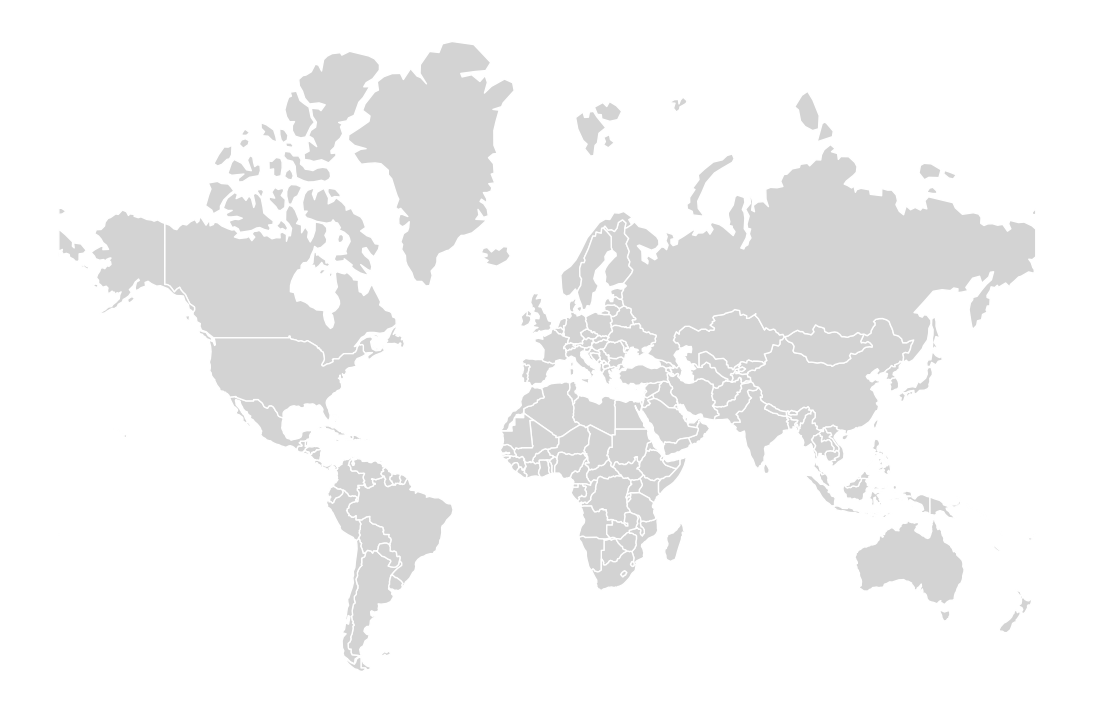

In [16]:
import matplotlib.pyplot as plt

ax = world.plot(
    figsize=(16, 9),
    color="lightgray",
    edgecolor="white"
)

ax.set_axis_off()

plt.show()

3. On top of the countries that you just plotted, plot another layer of information, namely the capital cities of each country from the <span style="font-weight: bold">cities</span> dataset. However, depending on how clever your programming environment is, the cities will probably all appear to be in the Gulf of Guinea, near the coordinates (0°, 0°).

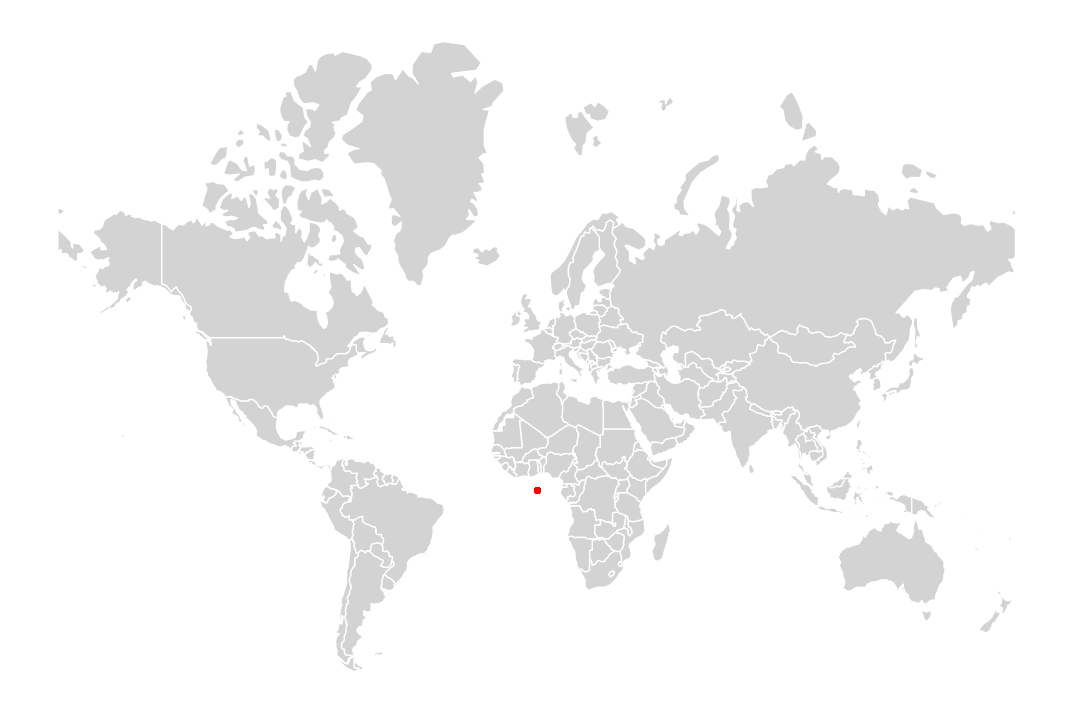

In [17]:
ax = world.plot(
    figsize=(16, 9),
    color="lightgray",
    edgecolor="white"
)

cities.plot(
    ax=ax,
    color="red",
    markersize=15
)

ax.set_axis_off()

plt.show()

4. Perform a map projection to bring the two data-sets into a shared coordinate system. (You can choose which one.) Now plot the two layers together to make sure the capital cities are where they are supposed to be.

In [18]:
print("World CRS:")
print(world.crs)

print("\nCities CRS:")
print(cities.crs)

World CRS:
EPSG:3395

Cities CRS:
EPSG:4326


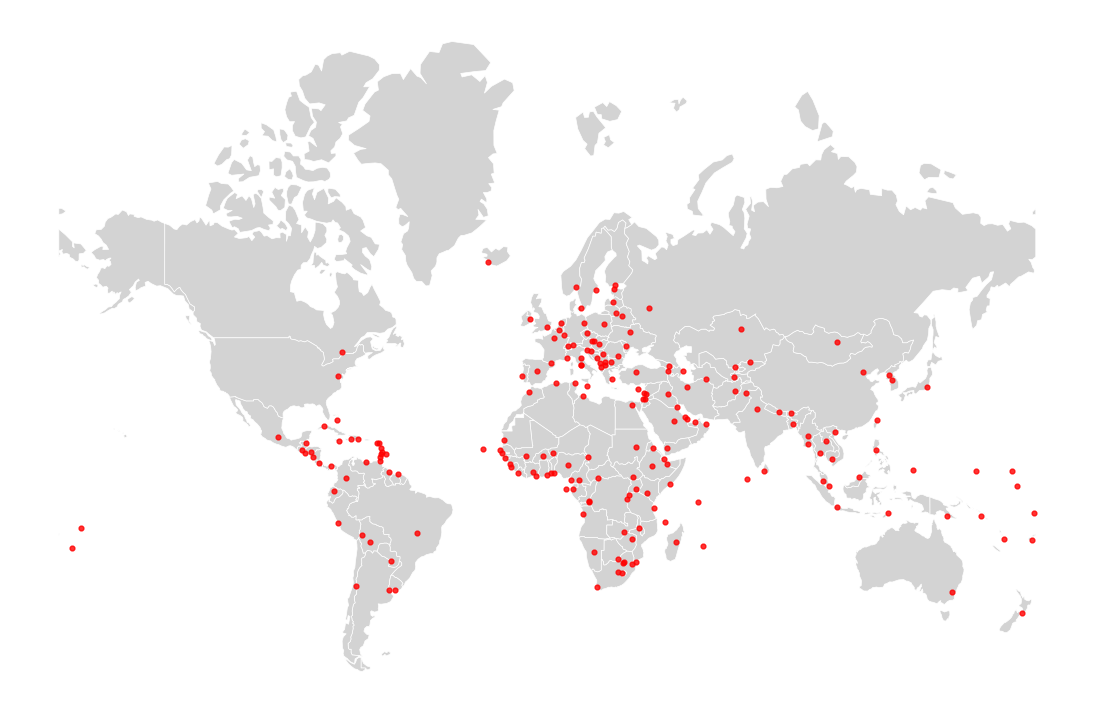

In [19]:
# Reproject cities from EPSG:4326 to the world's CRS, EPSG:3395
cities_3395 = cities.to_crs(world.crs)

# Plot both layers together
fig, ax = plt.subplots(figsize=(16, 9))

world.plot(
    ax=ax,
    color="lightgray",
    edgecolor="white",
    linewidth=0.5
)

cities_3395.plot(
    ax=ax,
    color="red",
    markersize=12,
    alpha=0.8
)

ax.set_axis_off()

plt.show()

**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

## Exercise 2 | Symbol classification

We’ll be looking into machine learning by checking out the [HASYv2](https://zenodo.org/record/259444#.Wb7efZ8xDhZ) dataset that contains hand written mathematical symbols as images. The whole dataset is quite big, so we’ll restrict ourselves to doing 10-class classification on some of the symbols. Download the data and complete the following tasks.

1. Extract the data and find inside a file called <span style="font-weight: bold">hasy-data-labels.csv</span>. This file contains the labels for each of the images in the <span style="font-weight: bold">hasy_data</span> folder. Read the labels in and only keep the rows where the <span style="font-weight: bold">symbol_id</span> is within the inclusive range <span style="font-weight: bold">[70, 79]</span>. Read the corresponding images as black-and-white images and flatten them so that each image is a single vector of shape <span style="font-weight: bold">32x32 = 1024</span>. Your dataset should now consist of your input data of shape <span style="font-weight: bold">(1020, 1024)</span> and your labels of shape <span style="font-weight: bold">(1020, )</span>. That is, a matrix of shape <span style="font-weight: bold">1020 x 1024</span> and a vector of size <span style="font-weight: bold">1020</span>.

In [74]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

# 1. Read the label file
labels = pd.read_csv("hasy-data-labels.csv")

# Inspect once to verify the CSV column names
print(labels.columns)
display(labels.head())

# 2. Keep only labels 70–79, inclusive
filtered_labels = labels[
    labels["symbol_id"].between(70, 79, inclusive="both")
].copy()

print(filtered_labels.shape)

print(filtered_labels.columns)

Index(['path', 'symbol_id', 'latex', 'user_id'], dtype='str')


,path,symbol_id,latex,user_id
0,hasy-data/v2-00000.png,31,A,50
1,hasy-data/v2-00001.png,31,A,10
2,hasy-data/v2-00002.png,31,A,43
3,hasy-data/v2-00003.png,31,A,43
4,hasy-data/v2-00004.png,31,A,4435


(1020, 4)
Index(['path', 'symbol_id', 'latex', 'user_id'], dtype='str')


In [75]:
images = []
labels = []

for _, row in filtered_labels.iterrows():
    image_path = row["path"]

    with Image.open(image_path) as img:
        grayscale_image = img.convert("L")
        image_vector = np.array(grayscale_image, dtype=np.float32).flatten()

    images.append(image_vector)
    labels.append(row["symbol_id"])

X = np.stack(images, axis=0)
y = np.array(labels)

print("Final shapes:")
print("  X:", X.shape)
print("  y:", y.shape)

Final shapes:
  X: (1020, 1024)
  y: (1020,)


2. Randomly shuffle the data, and then split it into training and test sets, using the first 80% of the data for training and the rest for evaluation.

In [76]:
# Reproducible random shuffle
rng = np.random.default_rng(seed=42)
indices = rng.permutation(len(X))

# Apply exactly the same shuffled order to X and y
X_shuffled = X[indices]
y_shuffled = y[indices]

# 80% training / 20% test
split_index = int(0.8 * len(X_shuffled))

X_train = X_shuffled[:split_index]
y_train = y_shuffled[:split_index]

X_test = X_shuffled[split_index:]
y_test = y_shuffled[split_index:]

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(816, 1024) (816,)
(204, 1024) (204,)


3. Fit a logistic regression classifier on the data. Note that we have a multi-class classification problem, but logistic regression is a binary classifier. For this reason, you will find useful <span style="font-weight: bold">[Sklearn's "multi_class" attribute](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)</span>. Use a multinomial loss and the softmax function to predict the probability of each class as the outcome.  The classifier should select the class with the highest probability. Most library implementations will do this for you - feel free to use one.

In [61]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Scale pixel values from [0, 255] to [0, 1]
X_train_scaled = X_train / 255.0
X_test_scaled = X_test / 255.0

# 2. Create multinomial logistic-regression model
# In your scikit-learn version, multinomial multiclass handling
# is automatic with solver="lbfgs", so do not use multi_class=...
model = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

# 3. Train the classifier
model.fit(X_train_scaled, y_train)

# 4. Predict the class label for each test image
y_pred = model.predict(X_test_scaled)

# 5. Predict the probability of every class for each test image
y_prob = model.predict_proba(X_test_scaled)

# 6. Inspect one prediction
print("Classes:", model.classes_)
print("\nProbabilities for first test image:", y_prob[0])
print("Probability sum:", y_prob[0].sum())
print("Predicted label:", y_pred[0])

# Confirm that the predicted label is the class with highest probability
highest_probability_index = np.argmax(y_prob[0])
manual_prediction = model.classes_[highest_probability_index]

print("Class with highest probability:", manual_prediction)


Classes: [70 71 72 73 74 75 76 77 78 79]

Probabilities for first test image: [2.9142800e-04 1.8983867e-04 1.8293650e-03 2.2875385e-04 5.4199091e-04
 3.5329473e-03 2.6528424e-02 3.9537917e-05 9.6487647e-01 1.9411800e-03]
Probability sum: 0.99999994
Predicted label: 78
Class with highest probability: 78


4. In order to evaluate the model, let’s create our own dummy classifier that simply guesses the most common class in the training set (looking at the test set here would be cheating!). Then, evaluate your logistic regression model on the test data, and compare it to the majority class classifier. The logistic regression model should have significantly better accuracy as the dummy model is merely making a guess.

    <span style="font-weight: 500"> *Hint: Sklearn's DummyClassifier( ) might save you a bit of time.*</span>

In [71]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
import numpy as np

# 1. Logistic-regression predictions and test accuracy
y_pred_logistic = model.predict(X_test_scaled)
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

# 2. Dummy model: always predicts the most frequent class in y_train
dummy_model = DummyClassifier(strategy="most_frequent")

# Fit only with TRAINING data — never use y_test here
dummy_model.fit(X_train_scaled, y_train)

# 3. Dummy predictions and test accuracy
y_pred_dummy = dummy_model.predict(X_test_scaled)
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)

# 4. Identify the majority class learned from y_train
majority_class = dummy_model.classes_[
    np.argmax(dummy_model.class_prior_)
]

# 5. Print the comparison
print("Most common training class:", majority_class)

print(f"\nLogistic regression accuracy: {logistic_accuracy:.4f}")
print(f"Logistic regression accuracy: {logistic_accuracy * 100:.2f}%")

print(f"\nDummy classifier accuracy: {dummy_accuracy:.4f}")
print(f"Dummy classifier accuracy: {dummy_accuracy * 100:.2f}%")

improvement = (logistic_accuracy - dummy_accuracy) * 100
print(f"\nImprovement: {improvement:.2f} percentage points")

Most common training class: 70

Logistic regression accuracy: 0.8824
Logistic regression accuracy: 88.24%

Dummy classifier accuracy: 0.1225
Dummy classifier accuracy: 12.25%

Improvement: 75.98 percentage points


5. Plot some of the images that the logistic classifier misclassified. Can you think of an explanation why they were misclassified? Would you have gotten them right?
    
    <span style="font-weight: 500">*Hint: Matplotlib has a [function](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html) that can help you with plotting.*</span>

Here are some examples of the syntax used to fit a logistic regression classifier (using Sklearn or statsmodel with Python, or GLM with R):

In [ ]:
#Sklearn (python)

#from sklearn.linear_model import LogisticRegression

#Fit on the training data set, with:
#X : {array-like, sparse matrix}, shape (n_samples, n_features) , n_samples rows x n_features columns
#with attributes that describe each sample.
#y : array-like, shape (n_samples,) , n_samples target values for each sample.

#model = LogisticRegression()
#model.fit(X, y)

In [ ]:
#Statsmodels (python)

#import statsmodels.api as sm
#model = sm.Logit(y, X)

In [ ]:
#GLM (R)

#model <- glm(y ~.,family=binomial(link='logit'), data=X)

Number of misclassified images: 24


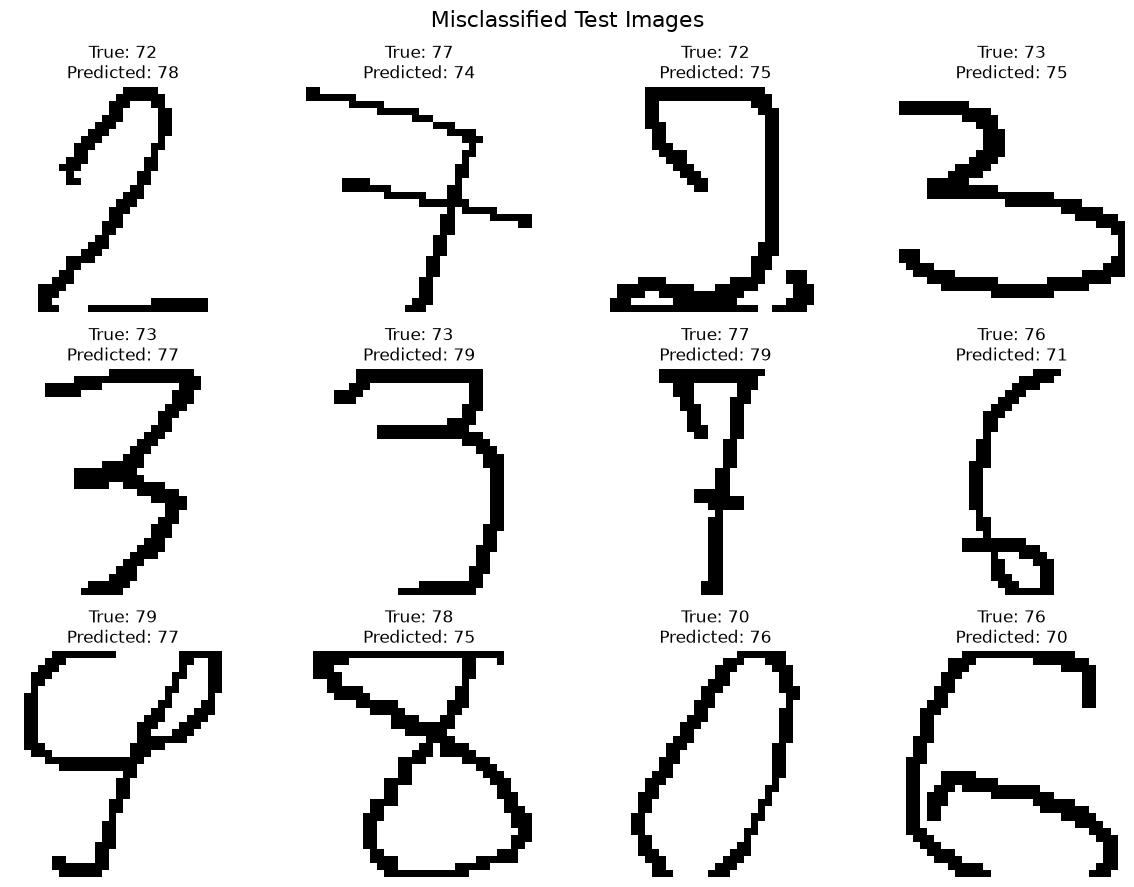

In [72]:
import numpy as np
import matplotlib.pyplot as plt

# Predict classes for the test images
y_pred = model.predict(X_test_scaled)

# Get locations where the prediction is wrong
misclassified_indices = np.where(y_pred != y_test)[0]

print("Number of misclassified images:", len(misclassified_indices))

# Plot up to 12 incorrectly classified images
n_images = min(12, len(misclassified_indices))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.ravel()

for i in range(n_images):
    index = misclassified_indices[i]

    # Reshape 1024 pixels back into the original 32 x 32 image
    image = X_test[index].reshape(32, 32)

    # Display the image
    axes[i].imshow(image, cmap="gray")

    # Show the actual and predicted class labels
    axes[i].set_title(
        f"True: {y_test[index]}\nPredicted: {y_pred[index]}"
    )

    axes[i].axis("off")

# Hide unused plot panels
for i in range(n_images, len(axes)):
    axes[i].axis("off")

plt.suptitle("Misclassified Test Images", fontsize=16)
plt.tight_layout()
plt.show()

The logistic-regression model misclassified some handwritten symbols because several images are visually ambiguous. The handwritings are faint, thick, rotated, shifted away from the centre, incomplete, or written in an unusual style. Some mathematical symbols also have similar shapes, so a small change in one stroke can make an image resemble another class.

A few misclassified images are difficult for me to recognise them with 100% certainty.

**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**